<a href="https://colab.research.google.com/github/feliciadominic14-create/Homework/blob/main/Practise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
filepath='/content/quickkart_customers.csv'
df = pd.read_csv(filepath)
df.head(3)

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   object 
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   object 
 3   City              1434 non-null   object 
 4   Membership        1500 non-null   object 
 5   Payment_Mode      1405 non-null   object 
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), object(5)
memory usage: 117.3+ KB


In [6]:
df.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0


In [7]:
#creating a column storing all numerical column names
num_Colmns=df.select_dtypes(include=["number"]).columns
#creating a column storing all categorical column names
Cat_colmns=df.select_dtypes(include=["object"]).columns
num_Colmns

Index(['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value',
       'Total_Spent'],
      dtype='object')

In [8]:
Cat_colmns

Index(['Customer_ID', 'Gender', 'City', 'Membership', 'Payment_Mode'], dtype='object')

In [9]:
type(num_Colmns)

pandas.core.indexes.base.Index

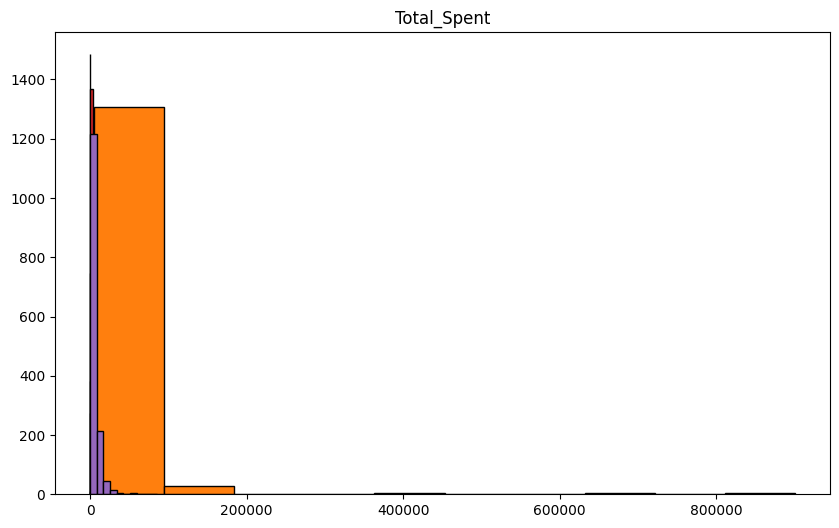

In [10]:
#plotting histogram of all numerical columns
plt.figure(figsize=[10,6])
for col in num_Colmns:
  plt.hist(df[col],edgecolor="Black")
  plt.title(col)
plt.show()

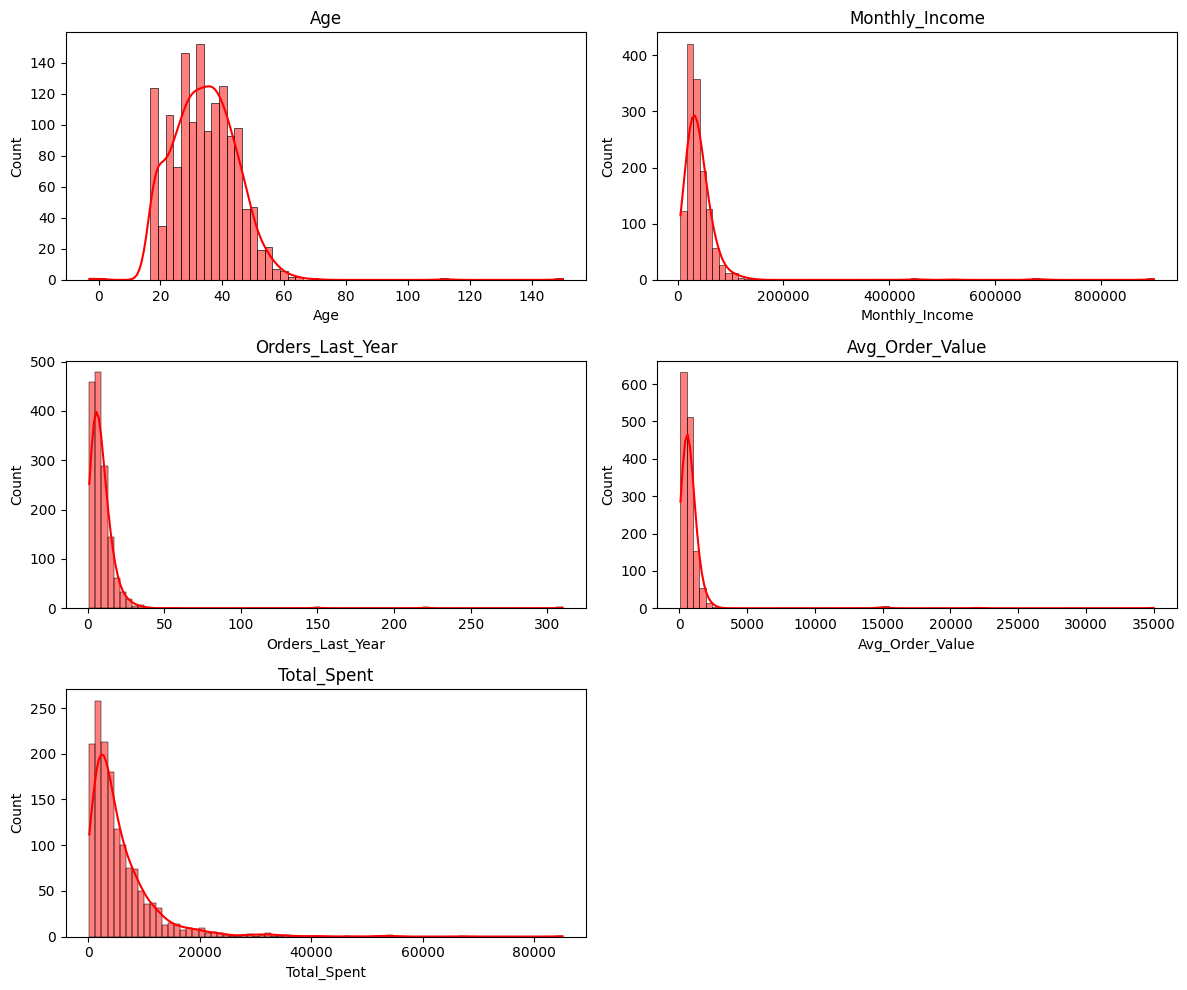

In [11]:
#creating a subplot to see all charts at once
import seaborn as sns
plt.figure(figsize=(12, 10))
for i,col in enumerate(num_Colmns,1):
  plt.subplot(3,2,i)
  sns.histplot(df[col],edgecolor="Black",color="Red",kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

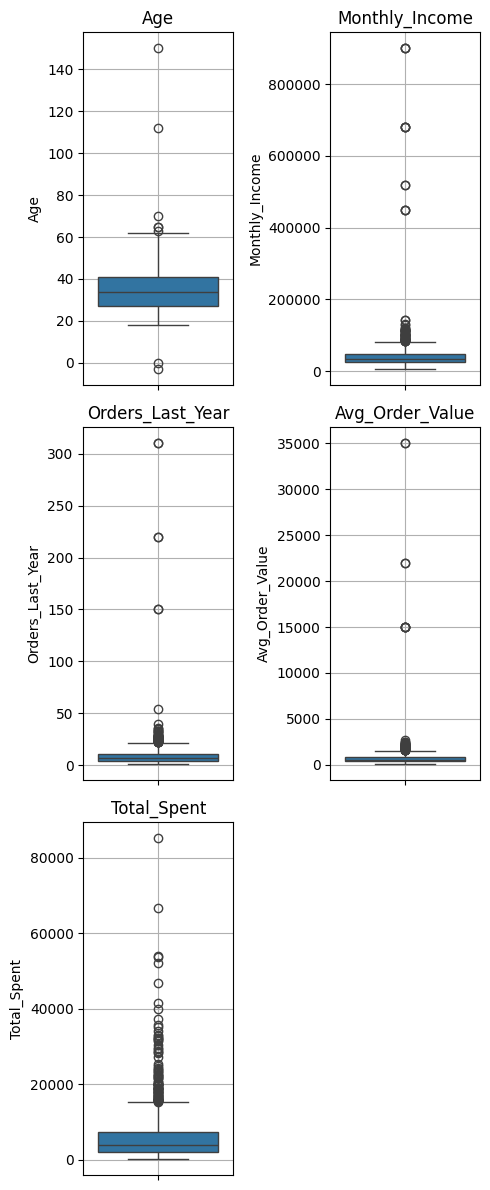

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5, 12))
for i,col in enumerate(num_Colmns,1):
  plt.subplot(3,2,i)
  sns.boxplot(df[col].dropna())
  plt.title(col)
  plt.grid()
plt.tight_layout()
plt.show()

In [13]:
#all column are skewed.
#null value handling
#strategy:use mean to replace
df.isna().sum()

,0
Customer_ID,0
Age,81
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [14]:
num_Colmns

Index(['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value',
       'Total_Spent'],
      dtype='object')

In [15]:
#replace the missing values with appropriate values
df["Age"].fillna(df["Age"].median(),inplace=True)
df["Monthly_Income"].fillna(df["Monthly_Income"].median(),inplace=True)
df["Orders_Last_Year"].fillna(df["Orders_Last_Year"].median(),inplace=True)
df["Avg_Order_Value"].fillna(df["Avg_Order_Value"].median(),inplace=True)
df["Total_Spent"].fillna(df["Total_Spent"].median(),inplace=True)

/tmp/ipykernel_680/2628708699.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].median(),inplace=True)
/tmp/ipykernel_680/2628708699.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try u

In [16]:
df.isna().sum()

,0
Customer_ID,0
Age,0
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


In [17]:
df["City"].value_counts()

,count
City,
Kochi,358
Trivandrum,230
Kozhikode,213
Thrissur,175
Kollam,144
Kannur,114
Alappuzha,113
Palakkad,73
kochi,3


In [18]:
Cat_colmns

Index(['Customer_ID', 'Gender', 'City', 'Membership', 'Payment_Mode'], dtype='object')

In [19]:
#assuming "Payment_Mode" is a target column
df["Payment_Mode"].unique()

array(['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery', nan,
       'Net Banking'], dtype=object)

In [20]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in ['Gender', 'City', 'Membership', 'Payment_Mode']:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])

df.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,1,7,0,2,55900.0,6.0,523.0,3143.0
1,C0758,36.0,3,10,6,4,47900.0,21.0,855.0,16395.0
2,C0993,18.0,3,10,0,4,32600.0,2.0,491.0,1007.0
3,C1171,32.0,1,4,2,1,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,1,4,2,0,81000.0,10.0,426.0,3915.0


In [21]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent']

scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

df.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,-0.510108,1,7,0,2,0.225956,-0.191915,-0.158759,-0.397319
1,C0758,0.172028,3,10,6,4,0.091953,0.771943,0.033181,1.642836
2,C0993,-1.582036,3,10,0,4,-0.164328,-0.448943,-0.177260,-0.726158
3,C1171,-0.217764,1,4,2,1,-0.159303,0.193628,0.565643,2.591018
4,C1069,-0.022868,1,4,2,0,0.646390,0.065114,-0.214838,-0.278469


In [22]:
df.isna().sum()

,0
Customer_ID,0
Age,0
Gender,0
City,0
Membership,0
Payment_Mode,0
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0
